# Deep analysis of data 

### Goal:
1. Analyzing the movements & positioning
2. Round outcome/ economy
3. Engagements & Utility usage

By analyzing all of these aspects in the game we will be able to paint a clearer picture of how our model works and reacts towards the data. Moreover, this will help us understand later in the line what adjustments we need to make on the model to help the model learn more efficient and have a more precise prediction of each player's movement throughout the CSGO round. 

In [1]:
import json
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
con = duckdb.connect()
for t in ["rounds", "round_players", "round_steps", "player_steps", "spotted_by", "utility"]:
    con.sql(f"CREATE VIEW {t} AS SELECT * FROM 'warehouse/{t}/*.parquet'")
con.sql("CREATE VIEW demos AS SELECT * FROM 'warehouse/demos.parquet'")

def q(sql):
    return con.sql(sql).df()

In [3]:
q("""
SELECT
    (SELECT count(*) FROM demos) AS demos,
    (SELECT count(*) FROM rounds) AS rounds,
    (SELECT count(*) FROM player_steps) AS player_rows,
    (SELECT round(avg(duration_s), 1) FROM rounds) AS avg_round_s,
    (SELECT round(avg((winner = 't')::INT) * 100, 1) FROM rounds WHERE winner IS NOT NULL) AS t_win_pct
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,demos,rounds,player_rows,avg_round_s,t_win_pct
0,420,8798,14532040,82.3,44.1


# 1: The goal is to analyze the movement and position of players overall and individually

In [4]:
# places where players are at pct of the time 

places = q("""
SELECT side, place,
        ROUND(count(*) * 100.0 / sum(count(*)) OVER (PARTITION BY side), 1) AS pct_time
FROM player_steps
WHERE is_alive = 1 AND place IS NOT NULL
GROUP BY side, place
ORDER BY side, pct_time DESC
""")
places.groupby("side").head(10)

,side,place,pct_time
0,ct,CTSpawn,24.1
1,ct,BombsiteA,18.0
2,ct,BombsiteB,12.2
3,ct,Catwalk,5.2
4,ct,Shop,4.8
5,ct,Underpass,4.2
6,ct,PalaceInterior,4.0
7,ct,SnipersNest,3.8
8,ct,Truck,3.7
9,ct,Connector,3.7


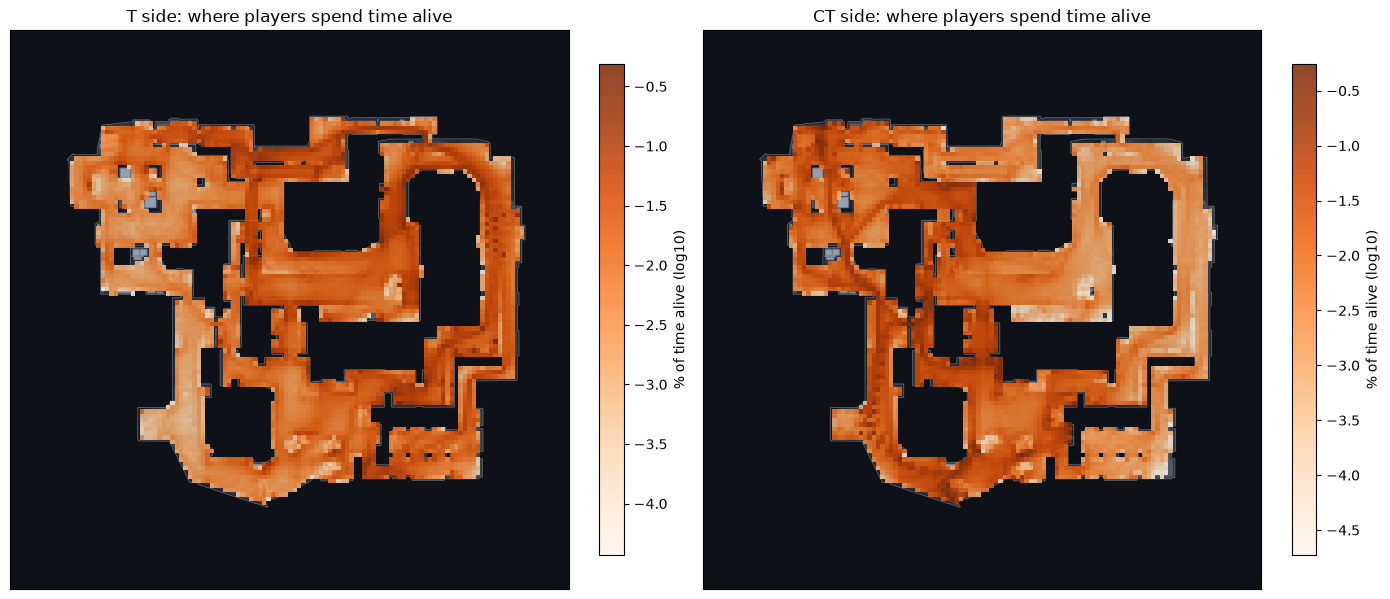

In [5]:
meta = json.load(open("assets/de_mirage_map.json"))
radar = plt.imread("assets/de_mirage_map.png")
xmin, xmax, ymin, ymax = meta["extent"]
BIN = 40

bins = q(f"""
SELECT side, 
        floor(x/ {BIN})::INT AS gx,
        floor(y/ {BIN})::INT AS gy,
        count(*) AS n
FROM player_steps
WHERE is_alive = 1
GROUP BY ALL 
""")

gx0, gy0 = int(np.floor(xmin / BIN)), int(np.floor(ymin / BIN))
nx, ny = int(np.ceil(xmax / BIN)) - gx0, int(np.ceil(ymax / BIN)) - gy0
grid_extent = (gx0 * BIN, (gx0 + nx) * BIN, gy0 * BIN, (gy0 + ny) * BIN)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (side, title) in zip(axes, [("t", "T side"), ("ct", "CT side")]):
    d = bins[bins.side == side]
    grid = np.zeros((ny, nx))
    ix, iy = d.gx.to_numpy() - gx0, d.gy.to_numpy() - gy0
    keep = (ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny)
    np.add.at(grid, (iy[keep], ix[keep]), d.n.to_numpy()[keep])
    share = grid / grid.sum() * 100  # % of the side's time alive in each cell

    ax.imshow(radar, extent=meta["extent"])
    im = ax.imshow(np.ma.masked_equal(np.log10(share + 1e-6), -6), origin="lower",
                   extent=grid_extent, cmap="Oranges", alpha=0.85)
    ax.set_title(f"{title}: where players spend time alive")
    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
    ax.set_xticks([]); ax.set_yticks([])
    cb = fig.colorbar(im, ax=ax, fraction=0.04)
    cb.set_label("% of time alive (log10)")
plt.tight_layout()
plt.show()

Analysis: 
Each team has a perspective rount or area on the map that players take when they are on either side. As expected, the teams frequent more on the side their team starts on. For example, the Terrorist (T) team tend to spend most of their time on the right side. Similarly, the Counter-Terrorist (CT) tend to roam all over their side of the map.

(Note for more findings analyzing this longer)

# 2: Round Outcome/ economy next


In [6]:
by_round = q("""
SELECT round_num,
       count(*) AS rounds,
       avg(t_cash_spent) AS t_spent,
       avg(ct_cash_spent) AS ct_spent,
       avg(t_equip) AS t_equip,
       avg(ct_equip) AS ct_equip
FROM rounds
WHERE t_players = 5 AND ct_players = 5
  AND round_num <= 24 -- regulation; overtime has its own fixed money
GROUP BY round_num
ORDER BY round_num
""")

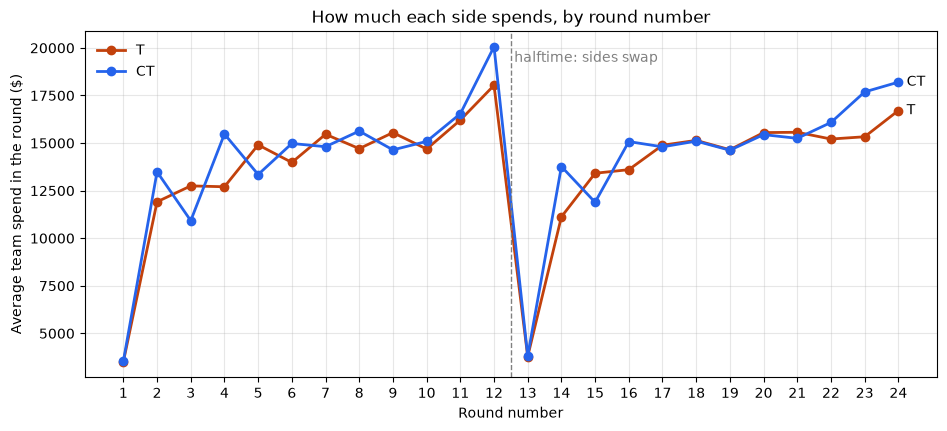

,round_num,rounds,t_spent,ct_spent,t_equip,ct_equip
0,1,310,3509.032258,3539.354839,4644.677419,4519.677419
1,2,420,11912.500000,13488.690476,13142.857143,15257.380952
2,3,419,12749.761337,10922.434368,18367.183771,19890.214797
3,4,420,12703.333333,15475.833333,18994.047619,24432.261905
4,5,418,14904.904306,13346.889952,21272.727273,24314.593301
5,6,417,13981.175060,14977.338129,20822.182254,26028.417266
6,7,418,15461.483254,14808.971292,22020.574163,25686.722488
7,8,418,14706.937799,15630.382775,21766.866029,26333.612440
8,9,417,15549.040767,14641.366906,21989.328537,25826.978417
9,10,416,14685.216346,15086.298077,21475.240385,26306.370192


In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for col, label, color in [("t_spent", "T", "#c2410c"), ("ct_spent", "CT", "#2563eb")]:
    ax.plot(by_round.round_num, by_round[col], marker="o", lw=2, color=color, label=label)
    ax.annotate(label, (by_round.round_num.iloc[-1], by_round[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color="black")
ax.axvline(12.5, color="gray", ls="--", lw=1)
ax.text(12.6, ax.get_ylim()[1] * 0.95, "halftime: sides swap", color="gray", va="top")
ax.set_xticks(range(1, 25))
ax.set_xlabel("Round number")
ax.set_ylabel(r"Average team spend in the round (\$)")
ax.set_title("How much each side spends, by round number")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()
by_round

Analysis: as expected, the more rounds there are in a game, the more likely both sides will have more money. That is why the plot is skewed left. However, there is a substantial difference between the two sides is CT tends to have more money the more rounds their on whenever they are playing on mirage. 

This is a little expected due to the T side have cheaper items compared to that of CT side. The assumption can be made that when looking at utility usage, there might be lower expected usage in the CT side than the T side. 

In [8]:
# buy-type mathcups -> T win rate
eco, full = 5000, 20000 # when a team is either full buying or eco meaning they are buying minimal gear to buy big next round

con.sql(f"""
CREATE OR REPLACE VIEW round_buys AS
SELECT *,
    CASE WHEN round_num IN (1, 13) THEN 'pistol'
         WHEN t_equip  < {eco}  THEN 'eco'
         WHEN t_equip  < {full} THEN 'force'
         ELSE 'full' END AS t_buy,
    CASE WHEN round_num IN (1, 13) THEN 'pistol'
         WHEN ct_equip < {eco}  THEN 'eco'
         WHEN ct_equip < {full} THEN 'force'
         ELSE 'full' END AS ct_buy
FROM rounds
WHERE winner IS NOT NULL AND t_players = 5 AND ct_players = 5
""")

In [10]:
m = q("""
SELECT t_buy, ct_buy,
    COUNT(*) AS rounds,
    ROUND(avg((winner = 't')::INT) * 100, 1) AS t_win_pct
FROM round_buys
WHERE t_buy <> 'pistol'
GROUP BY ALL
""")

In [11]:
order = ["eco", "force", "full"]
win = m.pivot(index="t_buy", columns="ct_buy", values="t_win_pct").reindex(index=order, columns=order)
n = m.pivot(index="t_buy", columns="ct_buy", values="rounds").reindex(index=order, columns=order)

print("T win % (rows = T buy, columns = CT buy); red = T favoured, blue = CT favoured")
display(win.style.background_gradient(cmap="RdBu_r", vmin=0, vmax=100).format("{:.1f}"))
print("Number of rounds in each cell")
display(n)

T win % (rows = T buy, columns = CT buy); red = T favoured, blue = CT favoured


ct_buy,eco,force,full
t_buy,,,
eco,47.1,0.0,4.4
force,92.5,70.6,25.0
full,93.3,69.2,45.4


Number of rounds in each cell


ct_buy,eco,force,full
t_buy,,,
eco,17,21,634
force,93,201,1558
full,299,953,4298


This displays the T win rate for every combination of what both teams bought. So meaning for T side, whenever the team ecos, and the ct side ecos they have a 47.1 % win rate. For when T side full buys while ct side ecos they have a higher win rate. This logically is sound because it reflects the advantage the T side has with gear compared to that of the CT side. 

Moreover the blue parts reflects the odds or the rate is higher for the CT side to win compared to that of the T side.

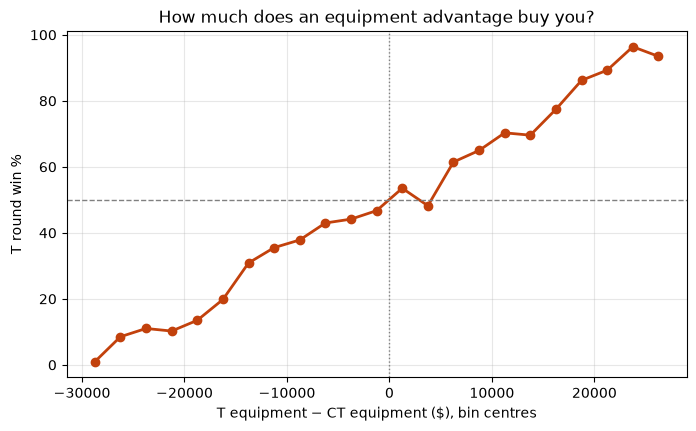

,diff_bin,rounds,t_win_pct
0,-30000,106,0.943396
1,-27500,176,8.522727
2,-25000,254,11.023622
3,-22500,410,10.243902
4,-20000,363,13.498623
5,-17500,207,19.806763
6,-15000,230,30.869565
7,-12500,335,35.522388
8,-10000,584,37.842466
9,-7500,877,42.987457


In [13]:
d = q("""
SELECT (floor((t_equip - ct_equip) / 2500) * 2500)::INT AS diff_bin,
    count(*) AS rounds,
    avg((winner = 't')::INT) * 100 AS t_win_pct
FROM round_buys
WHERE t_buy <> 'pistol'
GROUP BY ALL
HAVING COUNT(*) >= 30 -- droping thin bins
ORDER BY diff_bin
""")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(d.diff_bin + 1250, d.t_win_pct, marker="o", lw=2, color="#c2410c")
ax.axhline(50, color="gray", lw=1, ls="--")
ax.axvline(0, color="gray", lw=1, ls=":")
ax.set_xlabel("T equipment − CT equipment ($), bin centres")
ax.set_ylabel("T round win %")
ax.set_title("How much does an equipment advantage buy you?")
ax.grid(alpha=0.3)
plt.show()
d

This is a more clear depiction of equipment difference between both teams. With a clear difference in equipment cost the win rate is higher, supporting our claim earlier about how spending more money (in-game money) for better equipment in the game gives you a significant leverage in winning the round. 

# IMPORTANT Analysis: How much does inning the pistol round determine the outcome of the rest of the game

In [15]:
q("""
WITH pistols AS (
    SELECT demo, round_num, winner FROM rounds WHERE round_num IN (1, 13)
)
SELECT p.round_num AS pistol_round,
       r.round_num - p.round_num AS rounds_after,
       count(*) AS n,
       round(avg((r.winner = p.winner)::INT) * 100, 1) AS pistol_winner_win_pct
FROM pistols p
JOIN rounds r
    ON r.demo = p.demo
    AND r.round_num BETWEEN p.round_num + 1 AND p.round_num + 3
WHERE r.winner IS NOT NULL AND p.winner IS NOT NULL
GROUP BY ALL
ORDER BY ALL
""")

,pistol_round,rounds_after,n,pistol_winner_win_pct
0,1,1,310,80.3
1,1,2,310,60.0
2,1,3,310,48.7
3,13,1,413,86.2
4,13,2,406,58.1
5,13,3,396,52.5


From winning the pistol round the chances of winning the round after is higher however, it slowly starts to flatten the curve down more as more rounds occur because of the losing team gaining more money alowing the game to be more "balanced". 

This supports a hypothesis that as the team plays smarter by "eco" a round and attempting to buy more expensive gear, it levels the playing field leaving the win percentage to be around 50%. Meaning that the game despite CT spending more money than T side doesn't mean that either side has a higher chance of winning. However, the course of the game and the way how players play are what determine whether the team on either side is more likely to win or not. 

# Utility Engagement

In [21]:
opening = q("""
    SELECT 
        first_death_side,
        COUNT(*) AS side_that_died_first,
        ROUND(AVG((winner <> first_death_side)::INT) * 100, 1) AS opening_kill_side_win_pct,
        ROUND(MEDIAN(first_death_s), 1) AS median_first_death_s
    FROM rounds
    WHERE winner IS NOT NULL
      AND first_death_side IS NOT NULL
      AND t_players = 5
      AND ct_players = 5
    GROUP BY ALL
""")
opening

,first_death_side,side_that_died_first,opening_kill_side_win_pct,median_first_death_s
0,ct,3542,70.4,26.0
1,t,5012,74.7,25.5


Throghout all of the games the T side has the most deaths. However, that doesn't mean that it had a lower percent of winning. We see that they had a higher rate of winning by 4% which is signifcant since the difference are within the thousands. Though the distribution of each game is different with the median of first deths being around 25.5 for T side and 26 for CT side. 

In [23]:
first_deaths = q("""
    WITH firsts AS (
        SELECT 
            p.demo, 
            p.round_num, 
            p.slot, 
            p.side, 
            (p.death_s / 0.5)::INT - 1 AS step 
        FROM round_players p 
        JOIN rounds r USING (demo, round_num) 
        WHERE p.death_s = r.first_death_s 
          AND p.side = r.first_death_side 
    ) 
    SELECT 
        f.side AS victim_side, 
        ps.place, 
        COUNT(*) AS deaths 
    FROM firsts f 
    JOIN player_steps ps USING (demo, round_num, slot, step) 
    WHERE ps.place IS NOT NULL 
    GROUP BY ALL 
    ORDER BY deaths DESC 
""")
first_deaths.groupby("victim_side").head(10)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,victim_side,place,deaths
0,t,TopofMid,917
1,ct,BombsiteA,722
2,t,Apartments,632
3,t,Middle,552
4,t,BombsiteA,486
5,t,PalaceInterior,474
6,t,Catwalk,465
7,t,TRamp,369
8,ct,SnipersNest,330
9,ct,Middle,312


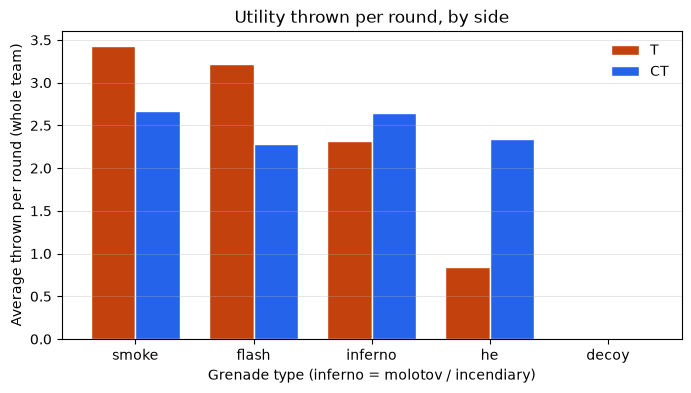

thrown_by,t,ct
kind,,
smoke,3.43,2.67
flash,3.22,2.28
inferno,2.31,2.65
he,0.84,2.34
decoy,0.02,0.01


In [24]:
# One row per thrown grenade (throw_id is shared by its flight, pop and smoke/fire).
util = q("""
WITH throws AS (
    SELECT DISTINCT demo, round_num, throw_id, thrown_by, kind
    FROM utility
    WHERE throw_id > 0
)
SELECT thrown_by, kind,
       count(*) * 1.0 / (SELECT count(*) FROM rounds) AS per_round
FROM throws
GROUP BY ALL
""")
per_round = util.pivot(index="kind", columns="thrown_by", values="per_round") \
                .reindex(["smoke", "flash", "inferno", "he", "decoy"])[["t", "ct"]]

ax = per_round.plot.bar(figsize=(8, 4), color=["#c2410c", "#2563eb"], width=0.75, edgecolor="white")
ax.set_xlabel("Grenade type (inferno = molotov / incendiary)")
ax.set_ylabel("Average thrown per round (whole team)")
ax.set_title("Utility thrown per round, by side")
ax.legend(["T", "CT"], frameon=False)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
plt.show()
per_round.round(2)

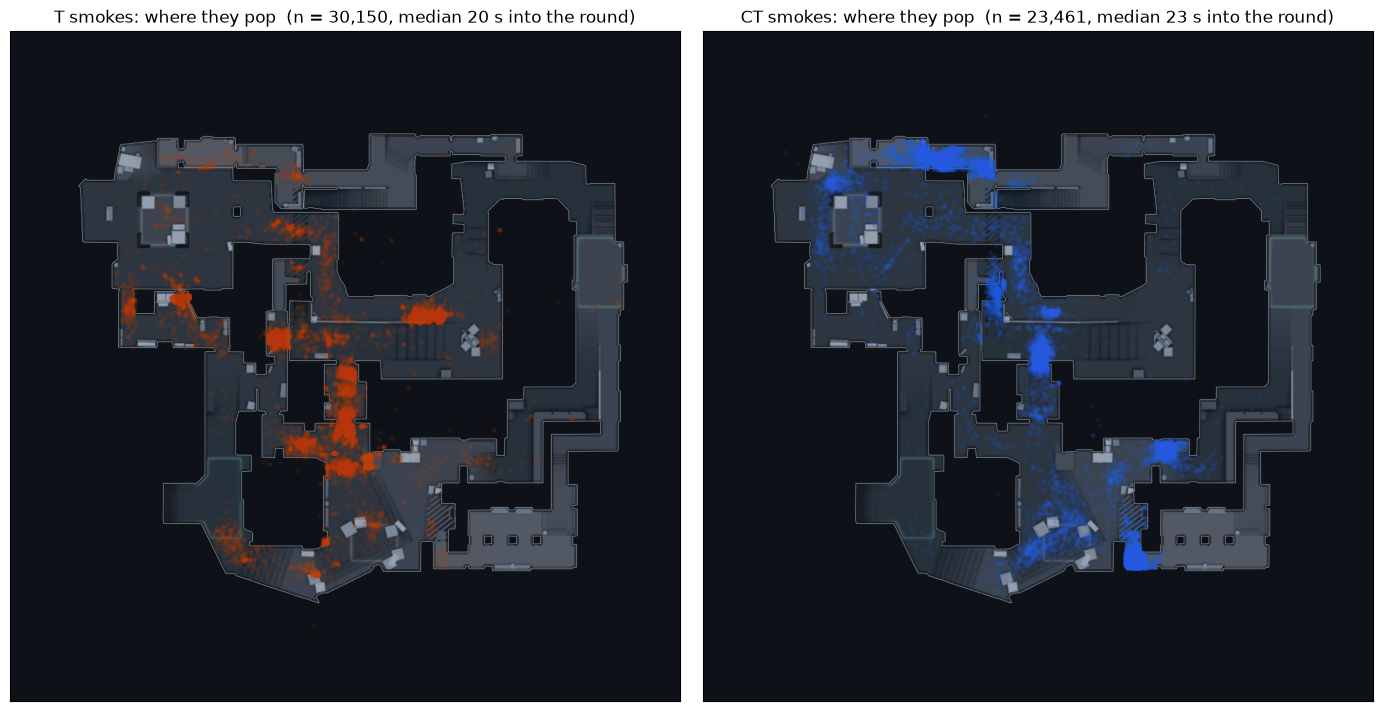

In [ ]:
# The first step a smoke is no longer in flight = where and when it popped.
smokes = q("""
SELECT thrown_by,
       arg_min(x, step) AS x,
       arg_min(y, step) AS y,
       min(step) * 0.5 AS pop_s
FROM utility
WHERE kind = 'smoke' AND in_flight = 0 AND throw_id > 0
GROUP BY demo, round_num, throw_id, thrown_by
""")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (side, title, color) in zip(axes, [("t", "T smokes", "#c2410c"), ("ct", "CT smokes", "#2563eb")]):
    d = smokes[smokes.thrown_by == side]
    ax.imshow(radar, extent=meta["extent"])
    ax.scatter(d.x, d.y, s=6, alpha=0.08, color=color)
    ax.set_title(f"{title}: where they pop  (n = {len(d):,}, median {d.pop_s.median():.0f} s into the round)")
    ax.set_xlim(meta["extent"][:2]); ax.set_ylim(meta["extent"][2:])
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()